In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, genextreme, genpareto


import yfinance as yf

V = 1_000_000
N_expected = 2555


In [3]:
ticker = "^GSPC"

df = yf.download(
    ticker,
    start="2011-11-01",
    end="2021-12-30",
    auto_adjust=False,
    progress=False
)

# Extract close price as a Series
prices = df["Close"]

if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]

prices = prices.dropna().sort_index()
prices.name = "SP500_Close"

print("First date:", prices.index[0])
print("Last date:", prices.index[-1])
print("Number of prices:", len(prices))
print(prices.head())


First date: 2011-11-01 00:00:00
Last date: 2021-12-29 00:00:00
Number of prices: 2557
Date
2011-11-01    1218.280029
2011-11-02    1237.900024
2011-11-03    1261.150024
2011-11-04    1253.229980
2011-11-07    1261.119995
Name: SP500_Close, dtype: float64


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


In [7]:
# Adjust sample to exactly 2556 closing prices
prices = prices.iloc[:-1].copy()

# Recalculate daily log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

# Linearized portfolio loss
V = 1_000_000
losses = -V * log_returns
losses.name = "Daily_Loss"

print("First date:", prices.index[0])
print("Last date:", prices.index[-1])
print("Number of prices:", len(prices))
print("Number of log returns:", len(log_returns))
print("Number of losses:", len(losses))

assert len(prices) == 2556
assert len(log_returns) == 2555

print("\nData validation passed!")


First date: 2011-11-01 00:00:00
Last date: 2021-12-28 00:00:00
Number of prices: 2556
Number of log returns: 2555
Number of losses: 2555

Data validation passed!


In [8]:
# Historical VaR
# 100 alpha values with the assigned increment
alphas = 0.99 + np.arange(100) * 0.000099

# Also evaluate the exact target alpha
target_alpha = 0.9999

historical_var = np.quantile(losses, alphas)
historical_var_9999 = np.quantile(losses, target_alpha)

print(f"Historical VaR 99.99%: ${historical_var_9999:,.2f}")


Historical VaR 99.99%: $120,575.74


In [9]:
theta = 0.97
lam = 0.97
init_window = 100

# Only use information available as of Nov 1, 2021
returns_ewma = log_returns.loc[:"2021-11-01"]

r = returns_ewma.to_numpy()

mu = np.mean(r[:init_window])
variance = np.var(r[:init_window], ddof=1)

for x in r[init_window:]:
    old_mu = mu
    old_variance = variance

    mu = theta * old_mu + (1 - theta) * x

    variance = (
        lam * old_variance
        + (1 - lam) * (x - old_mu)**2
    )

sigma = np.sqrt(variance)

print(f"EWMA forecast mean: {mu:.8f}")
print(f"EWMA forecast volatility: {sigma:.8f}")
print("Last observation:", returns_ewma.index[-1])


EWMA forecast mean: 0.00121010
EWMA forecast volatility: 0.00722707
Last observation: 2021-11-01 00:00:00


In [10]:
normal_var = -V * mu + V * sigma * norm.ppf(alphas)

normal_var_9999 = (
    -V * mu
    + V * sigma * norm.ppf(target_alpha)
)

print(f"EWMA Normal VaR 99.99%: ${normal_var_9999:,.2f}")


EWMA Normal VaR 99.99%: $25,667.50


In [17]:
#GEV: Block Maxima Method

from scipy.optimize import minimize
from scipy.stats import genextreme
import numpy as np

def fit_gev_block_maxima(loss_data, block_size):
    values = np.asarray(loss_data, dtype=float)
    assert len(values) % block_size == 0

    n_blocks = len(values) // block_size
    maxima = values.reshape(n_blocks, block_size).max(axis=1)

    # Normalize the data for numerical stability
    center = maxima.mean()
    scale_factor = maxima.std()
    z = (maxima - center) / scale_factor

    # Multiple starting points for the MLE
    starts = []
    for c0 in [-0.8, -0.4, -0.1, 0.0, 0.2, 0.5]:
        starts.append([c0, np.median(z), np.log(0.8)])
        starts.append([c0, np.mean(z), np.log(1.0)])

    def neg_log_likelihood(params):
        c, loc, log_scale = params
        scale = np.exp(log_scale)

        logpdf = genextreme.logpdf(
            z, c=c, loc=loc, scale=scale
        )

        if not np.all(np.isfinite(logpdf)):
            return 1e12

        return -np.sum(logpdf)

    fits = []
    for start in starts:
        res = minimize(
            neg_log_likelihood,
            start,
            method="Nelder-Mead",
            options={"maxiter": 10000,
                     "xatol": 1e-9,
                     "fatol": 1e-9}
        )
        if res.success and np.isfinite(res.fun):
            fits.append(res)

    if not fits:
        raise RuntimeError("GEV fitting failed")

    best = min(fits, key=lambda r: r.fun)

    c, loc_z, log_scale_z = best.x

    mu = center + loc_z * scale_factor
    sigma = np.exp(log_scale_z) * scale_factor
    xi = -c

    return {
        "n": block_size,
        "m": n_blocks,
        "xi": xi,
        "mu": mu,
        "sigma": sigma,
        "maxima": maxima,
        "log_likelihood": -best.fun
    }

gev_73 = fit_gev_block_maxima(losses, 73)
gev_35 = fit_gev_block_maxima(losses, 35)

for res in [gev_73, gev_35]:
    print(f"\nBlock Size: {res['n']}")
    print(f"xi: {res['xi']:.6f}")
    print(f"mu: {res['mu']:.2f}")
    print(f"sigma: {res['sigma']:.2f}")
    print(f"Log likelihood: {res['log_likelihood']:.4f}")



Block Size: 73
xi: 0.181496
mu: 20958.18
sigma: 8732.72
Log likelihood: -30.2395

Block Size: 35
xi: 0.214112
mu: 15298.83
sigma: 8246.15
Log likelihood: -69.5879


In [18]:
def gev_var(alpha, result):
    xi = result["xi"]
    mu = result["mu"]
    sigma = result["sigma"]
    n = result["n"]

    alpha = np.asarray(alpha)
    z = -n * np.log(alpha)

    if abs(xi) < 1e-8:
        return mu - sigma * np.log(z)

    return mu + (sigma / xi) * (z**(-xi) - 1)


gev_var_73 = gev_var(alphas, gev_73)
gev_var_35 = gev_var(alphas, gev_35)

gev_73_9999 = float(gev_var(target_alpha, gev_73))
gev_35_9999 = float(gev_var(target_alpha, gev_35))

print(f"GEV (n=73) VaR 99.99%: ${gev_73_9999:,.2f}")
print(f"GEV (n=35) VaR 99.99%: ${gev_35_9999:,.2f}")


GEV (n=73) VaR 99.99%: $90,353.40
GEV (n=35) VaR 99.99%: $106,041.45


In [19]:
u = np.quantile(losses, 0.95)

exceeding_losses = losses[losses > u]

excesses = exceeding_losses - u

Nu = len(excesses)
N = len(losses)

print(f"Threshold u: ${u:,.2f}")
print(f"Total observations: {N}")
print(f"Exceedances: {Nu}")
print(f"Empirical F(u): {1 - Nu/N:.6f}")


Threshold u: $15,244.99
Total observations: 2555
Exceedances: 128
Empirical F(u): 0.949902


In [20]:
xi_gp, loc_gp, beta_gp = genpareto.fit(
    excesses.to_numpy(),
    floc=0
)

print(f"GP xi: {xi_gp:.6f}")
print(f"GP beta: {beta_gp:.4f}")
print(f"GP location: {loc_gp}")


GP xi: 0.273170
GP beta: 7469.8947
GP location: 0


In [21]:
def gp_var(alpha, u, xi, beta, Fu=0.95):
    alpha = np.asarray(alpha)

    ratio = (1 - Fu) / (1 - alpha)

    if abs(xi) < 1e-8:
        return u + beta * np.log(ratio)

    return u + beta / xi * (ratio**xi - 1)


gp_var_values = gp_var(
    alphas, u, xi_gp, beta_gp
)

gp_var_9999 = float(
    gp_var(target_alpha, u, xi_gp, beta_gp)
)

print(f"GP VaR 99.99%: ${gp_var_9999:,.2f}")


GP VaR 99.99%: $137,233.82


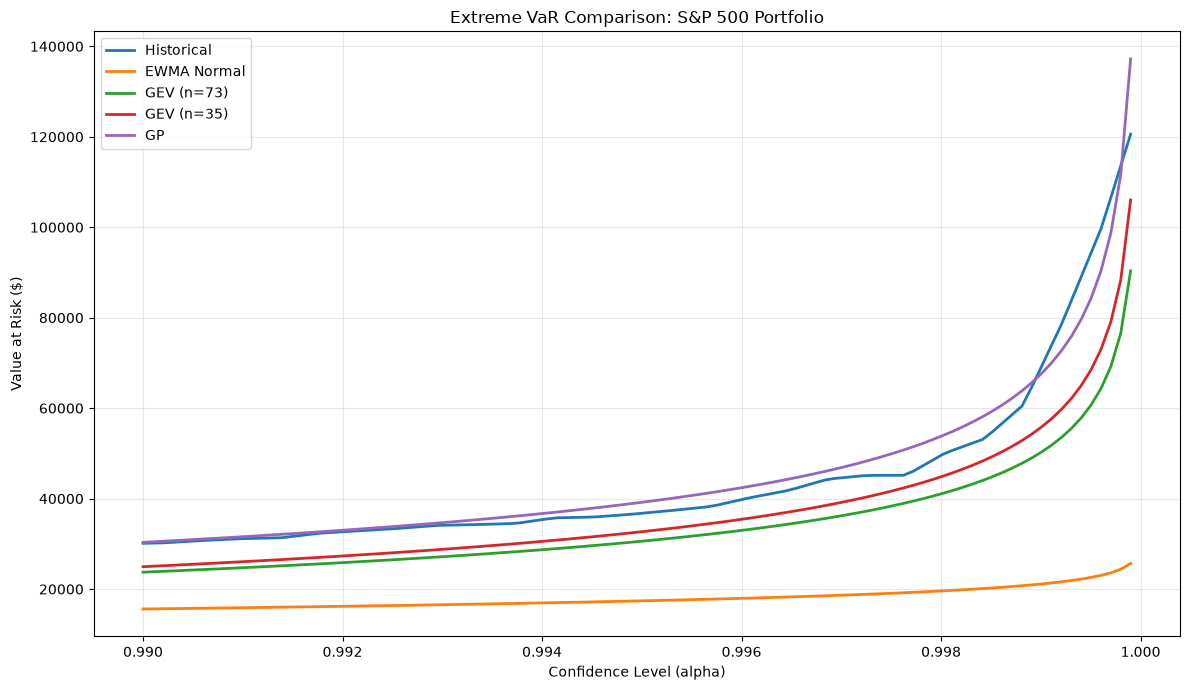

In [22]:
#Comparison Plot

plot_alphas = np.append(alphas, target_alpha)

plot_results = {
    "Historical": np.quantile(losses, plot_alphas),
    "EWMA Normal": -V*mu + V*sigma*norm.ppf(plot_alphas),
    "GEV (n=73)": gev_var(plot_alphas, gev_73),
    "GEV (n=35)": gev_var(plot_alphas, gev_35),
    "GP": gp_var(plot_alphas, u, xi_gp, beta_gp)
}

plt.figure(figsize=(12, 7))

for label, values in plot_results.items():
    plt.plot(plot_alphas, values, label=label, linewidth=2)

plt.xlabel("Confidence Level (alpha)")
plt.ylabel("Value at Risk ($)")
plt.title("Extreme VaR Comparison: S&P 500 Portfolio")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:
results = pd.DataFrame({
    "Method": ["Historical", "EWMA Normal",
               "GEV n=73", "GEV n=35", "GP"],
    "VaR_99.99": [
        historical_var_9999,
        normal_var_9999,
        gev_73_9999,
        gev_35_9999,
        gp_var_9999
    ]
})

print(results.to_string(index=False))
print("\nHighest VaR:", results.loc[
    results["VaR_99.99"].idxmax(), "Method"
])

print("\nGEV difference: $",
      abs(gev_73_9999 - gev_35_9999))

print("GP vs GEV n=73: $",
      gp_var_9999 - gev_73_9999)

print("GP vs GEV n=35: $",
      gp_var_9999 - gev_35_9999)


     Method     VaR_99.99
 Historical 120575.741542
EWMA Normal  25667.498619
   GEV n=73  90353.401069
   GEV n=35 106041.447260
         GP 137233.821876

Highest VaR: GP

GEV difference: $ 15688.046191083398
GP vs GEV n=73: $ 46880.42080652551
GP vs GEV n=35: $ 31192.37461544211
